# Практическая работа № 2

## Постановка задачи

Тема: "Рекомендательные системы"  
Выполнил: Алиев Эльчин Алойсатович  
Группа: КИ24-17/1б

Цель: Изучить методы и инструменты для создания рекомендательных систем
Задачи: 
1. Выбрать набор данных из представленных в открытом доступе (Kaggle и другие источники)
2. Прочитать данные. Провести разведочный анализ и выполнить предварительную обработку данных.
3. Реализовать алгоритмы рекомендательных систем:
    1. item-based и user-based подход
    2. модель подсчета рейтинга с использованием кластеризации (количество кластеров обосновать)
    3. матричная факторизация SVD и/или NMF
4. Протестировать. Сравнить результаты. Сделать выводы.  


## Выбор набора данных

Этот набор данных содержит информацию о предпочтениях 73 516 пользователей в отношении 12 294 аниме. Пользователи могут добавлять аниме в список просмотренного и выставлять оценки; данный набор данных представляет собой свод этих оценок.

Anime.csv:
anime_id — уникальный идентификатор аниме на сайте myanimelist.net.
name — полное название аниме.
genre — список жанров данного аниме, разделенных запятыми.
type — тип (фильм, сериал, OVA и т. д.).
episodes — количество эпизодов в аниме (1, если это фильм).
rating — средняя оценка аниме (по 10-балльной шкале).
members — количество участников сообщества, добавивших это аниме в свой список.


Rating.csv:
user_id — анонимный, случайно сгенерированный идентификатор пользователя.
anime_id — идентификатор аниме, оцененного пользователем.
rating — оценка, выставленная пользователем (по 10-балльной шкале; -1, если пользователь смотрел аниме, но не поставил оценку).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

import kagglehub

# Download latest version
path = kagglehub.dataset_download("CooperUnion/anime-recommendations-database")

print("Path to dataset files:", path)

C:\Users\el_jin\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\el_jin\.cache\kagglehub\datasets\CooperUnion\anime-recommendations-database\versions\1


In [2]:
anime = pd.read_csv(f'{path}/anime.csv')
rating = pd.read_csv(f'{path}/rating.csv')

In [3]:
anime

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266
...,...,...,...,...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1,4.15,211
12290,5543,Under World,Hentai,OVA,1,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1,4.98,175


In [4]:
anime.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB


In [5]:
anime.isna().sum()

anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

Можно увидеть наличие пропусков, однако их количество очень мало, поэтому можем просто удалить их.

In [6]:
anime = anime.dropna().reset_index(drop=True)

In [7]:
anime['episodes'].unique()

array(['1', '64', '51', '24', '10', '148', '110', '13', '201', '25', '22',
       '75', '4', '26', '12', '27', '43', '74', '37', '2', '11', '99',
       'Unknown', '39', '101', '47', '50', '62', '33', '112', '23', '3',
       '94', '6', '8', '14', '7', '40', '15', '203', '77', '291', '120',
       '102', '96', '38', '79', '175', '103', '70', '153', '45', '5',
       '21', '63', '52', '28', '145', '36', '69', '60', '178', '114',
       '35', '61', '34', '109', '20', '9', '49', '366', '97', '48', '78',
       '358', '155', '104', '113', '54', '167', '161', '42', '142', '31',
       '373', '220', '46', '195', '17', '1787', '73', '147', '127', '16',
       '19', '98', '150', '76', '53', '124', '29', '115', '224', '44',
       '58', '93', '154', '92', '67', '172', '86', '30', '276', '59',
       '72', '330', '41', '105', '128', '137', '56', '55', '65', '243',
       '193', '18', '191', '180', '91', '192', '66', '182', '32', '164',
       '100', '296', '694', '95', '68', '117', '151', '130',

In [8]:
anime = anime[~(anime['episodes'] == 'Unknown')]

In [9]:
rating

,user_id,anime_id,rating
0,1,20,-1
1,1,24,-1
2,1,79,-1
3,1,226,-1
4,1,241,-1
...,...,...,...
7813732,73515,16512,7
7813733,73515,17187,9
7813734,73515,22145,10
7813735,73516,790,9


In [10]:
rating.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7813737 entries, 0 to 7813736
Data columns (total 3 columns):
 #   Column    Dtype
---  ------    -----
 0   user_id   int64
 1   anime_id  int64
 2   rating    int64
dtypes: int64(3)
memory usage: 178.8 MB


In [11]:
rating.isna().sum()

user_id     0
anime_id    0
rating      0
dtype: int64

In [12]:
rating = rating[rating['anime_id'].isin(anime['anime_id'])].reset_index(drop=True)

In [13]:
rating

,user_id,anime_id,rating
0,1,20,-1
1,1,24,-1
2,1,79,-1
3,1,226,-1
4,1,241,-1
...,...,...,...
7813602,73515,16512,7
7813603,73515,17187,9
7813604,73515,22145,10
7813605,73516,790,9


In [14]:
rating = rating.rename(columns={'rating': 'rate'})

<Axes: >

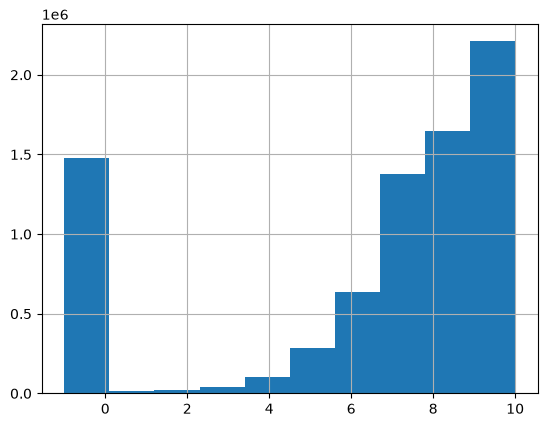

In [15]:
rating['rate'].hist()

In [16]:
df = pd.merge(rating, anime, how='inner', on='anime_id')

In [17]:
df

,user_id,anime_id,rate,name,genre,type,episodes,rating,members
0,1,20,-1,Naruto,"Action, Comedy, Martial Arts, Shounen, Super P...",TV,220,7.81,683297
1,1,24,-1,School Rumble,"Comedy, Romance, School, Shounen",TV,26,8.06,178553
2,1,79,-1,Shuffle!,"Comedy, Drama, Ecchi, Fantasy, Harem, Magic, R...",TV,24,7.31,158772
3,1,226,-1,Elfen Lied,"Action, Drama, Horror, Psychological, Romance,...",TV,13,7.85,623511
4,1,241,-1,Girls Bravo: First Season,"Comedy, Ecchi, Fantasy, Harem, Romance, School",TV,11,6.69,84395
...,...,...,...,...,...,...,...,...,...
7813602,73515,16512,7,Devil Survivor 2 The Animation,"Action, Demons, Supernatural",TV,13,7.06,101266
7813603,73515,17187,9,Ghost in the Shell: Arise - Border:1 Ghost Pain,"Mecha, Police, Psychological, Sci-Fi",Movie,1,7.64,31747
7813604,73515,22145,10,Kuroshitsuji: Book of Circus,"Comedy, Demons, Fantasy, Historical, Shounen, ...",TV,10,8.37,122895
7813605,73516,790,9,Ergo Proxy,"Mystery, Psychological, Sci-Fi",TV,23,8.03,265005


## 3. Реализация алгоритмов рекомендательных систем

In [18]:
rating_clean = rating[rating['rate'] != -1].copy()

In [19]:
rating_clean

,user_id,anime_id,rate
47,1,8074,10
81,1,11617,10
83,1,11757,10
101,1,15451,10
153,2,11771,10
...,...,...,...
7813602,73515,16512,7
7813603,73515,17187,9
7813604,73515,22145,10
7813605,73516,790,9


In [20]:
def train_test_split(df, ratio=0.2, user_col='user_id', item_col='anime_id', rating_col='rate'):
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)
    counts = df.groupby(user_col).cumcount()
    totals = df.groupby(user_col)[item_col].transform('count')
    
    test_mask = counts >= (totals * (1 - ratio))
    
    train_df = df[~test_mask]
    test_df = df[test_mask]
    
    return (train_df[[user_col, item_col]], 
            test_df[[user_col, item_col]], 
            train_df[rating_col].values, 
            test_df[rating_col].values)

In [21]:
class ItemBasedMethod():
    def fit(self, X, y, user_col='user_id', item_col='anime_id'):
        X = X.copy()
        self.users = X[user_col].unique()
        self.items = X[item_col].unique()
        X['y'] = y
        self.mean_y_user = X.groupby(user_col)['y'].mean()
        self.mean_y_item = X.groupby(item_col)['y'].mean()
        X['y'] -= X[item_col].apply(lambda x: self.mean_y_item[x])
        self.item_ratings = pd.pivot_table(X, values='y', index=item_col,
                                           columns=user_col, fill_value=0)
        self.item_sim = cosine_similarity(self.item_ratings)
    
        self.item_pos = dict()
        for item in self.items:
            self.item_pos[item] = np.argwhere(self.item_ratings.index.values == item)[0][0]
        return self
    
    def predict_rating(self, pr_user, pr_item):
        if not pr_item in self.items or not pr_user in self.users:
            return 0
        numerator = self.item_sim[self.item_pos[pr_item]].dot(
                        self.item_ratings.loc[:, pr_user])
        denominator = self.item_sim[self.item_pos[pr_item]].sum() - 1
        return self.mean_y_item[pr_item] + numerator / denominator
    
    def predict(self, X, user_col='user_id', item_col='anime_id'):
        y = X[[user_col, item_col]].apply(lambda row: self.predict_rating(row[0], row[1]), axis=1)
        return y

In [22]:
class UserBasedMethod:
    def fit(self, X, y, user_col='user_id', item_col='anime_id'):
        X = X[[user_col, item_col]].copy()
        X['y'] = y
        
        self.users = set(X[user_col].unique())
        self.items = set(X[item_col].unique())
        
        # Векторизованный расчет средних через map
        self.mean_y_user = X.groupby(user_col)['y'].mean()
        self.mean_y_item = X.groupby(item_col)['y'].mean()
        X['y'] -= X[user_col].map(self.mean_y_user)
        
        # Построение матрицы оценок
        user_ratings_df = pd.pivot_table(X, values='y', index=user_col,
                                         columns=item_col, fill_value=0)
        
        # Матрица сходства
        self.user_sim = cosine_similarity(user_ratings_df.values)
        
        # Быстрый маппинг в O(N) вместо O(N^2)
        self.user_pos = {uid: i for i, uid in enumerate(user_ratings_df.index)}
        self.item_pos = {iid: j for j, iid in enumerate(user_ratings_df.columns)}
        
        # Кэшируем сырой массив и знаменатели
        self.R_matrix = user_ratings_df.values
        self.mean_user_dict = self.mean_y_user.to_dict()
        # Предрассчитанный знаменатель: sum(sim) - 1
        self.denominators = self.user_sim.sum(axis=1) - 1.0
        
        return self

    def predict(self, X, user_col='user_id', item_col='anime_id'):
        u_vals = X[user_col].to_numpy()
        i_vals = X[item_col].to_numpy()
        preds = np.zeros(len(X), dtype=np.float64)
        
        user_pos = self.user_pos
        item_pos = self.item_pos
        user_sim = self.user_sim
        R_matrix = self.R_matrix
        denoms = self.denominators
        mean_user = self.mean_user_dict
        
        # Быстрый прямой цикл по массивам NumPy (без .apply и без pandas.Series)
        for idx in range(len(preds)):
            u = u_vals[idx]
            i = i_vals[idx]
            
            if u not in user_pos or i not in item_pos:
                preds[idx] = 0.0
                continue
                
            u_idx = user_pos[u]
            i_idx = item_pos[i]
            
            denom = denoms[u_idx]
            sim_row = user_sim[u_idx]
            item_col_ratings = R_matrix[:, i_idx]
            
            if denom != 0:
                preds[idx] = mean_user[u] + np.dot(sim_row, item_col_ratings) / denom
            else:
                preds[idx] = mean_user[u]
                
        return preds

## Подготовка данных для сравнения методов

Полная матрица «пользователь × аниме» (73 тыс. × 11 тыс.) не помещается в память в плотном виде. Поэтому для всех алгоритмов берём одну общую подвыборку:

1500 самых популярных аниме (у редких аниме слишком мало оценок для надёжной статистики);

5000 случайных активных пользователей (не менее 30 оценок).

Оценки -1 (просмотрено без оценки) уже удалены в rating_clean. Разбиение на train/test делается по каждому пользователю.

In [23]:
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF
from sklearn.metrics import silhouette_score, mean_absolute_error
from scipy.sparse.linalg import svds

top_items = rating_clean['anime_id'].value_counts().head(1500).index
sub = rating_clean[rating_clean['anime_id'].isin(top_items)]

user_cnt = sub['user_id'].value_counts()
active_users = user_cnt[user_cnt >= 30].index
np.random.seed(42)
users_sample = np.random.choice(active_users, size=min(5000, len(active_users)), replace=False)
sub = sub[sub['user_id'].isin(users_sample)].reset_index(drop=True)

X_tr, X_te, y_tr, y_te = train_test_split(sub)

idx = np.random.choice(len(X_te), size=min(10000, len(X_te)), replace=False)
X_te_s = X_te.iloc[idx].reset_index(drop=True)
y_te_s = y_te[idx]

print('Оценок в подвыборке:', len(sub))
print('Пользователей:', sub['user_id'].nunique(), '| Аниме:', sub['anime_id'].nunique())
print('Разреженность матрицы: %.1f%% заполнено' % (100 * len(sub) / (sub['user_id'].nunique() * sub['anime_id'].nunique())))
print('train:', len(X_tr), '| test:', len(X_te), '| тестовая выборка:', len(X_te_s))

Оценок в подвыборке: 625242
Пользователей: 5000 | Аниме: 1500
Разреженность матрицы: 8.3% заполнено
train: 502212 | test: 123030 | тестовая выборка: 10000


## Метрики и базовые модели

Качество измеряем метриками MAE и RMSE

Чтобы понимать, насколько хороши сложные методы, добавляем два простых базовых ориентира: глобальное среднее и средний рейтинг конкретного аниме. Если сложная модель не бьёт эти baseline, она бесполезна.

In [24]:
global_mean = y_tr.mean()
results = {}

def evaluate(name, y_true, y_pred):
    y_pred = np.asarray(y_pred, dtype=float).copy()
    unknown = (y_pred == 0)      
    y_pred[unknown] = global_mean
    y_pred = np.clip(y_pred, 1, 10) 
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    results[name] = {'MAE': mae, 'RMSE': rmse}
    print(f'{name}: MAE = {mae:.4f}, RMSE = {rmse:.4f}')

train_full = X_tr.copy()
train_full['rate'] = y_tr
item_mean = train_full.groupby('anime_id')['rate'].mean()

evaluate('Глобальное среднее', y_te_s, np.full(len(y_te_s), global_mean))
evaluate('Среднее по аниме', y_te_s, X_te_s['anime_id'].map(item_mean).fillna(global_mean).values)

Глобальное среднее: MAE = 1.1772, RMSE = 1.5385
Среднее по аниме: MAE = 1.1082, RMSE = 1.4360


## 3.1. Item-based и user-based подходы

Используем классы ItemBasedMethod и UserBasedMethod, реализованные выше

In [25]:
item_based = ItemBasedMethod().fit(X_tr, y_tr)
pred_item = item_based.predict(X_te_s)
evaluate('Item-based', y_te_s, pred_item)

C:\Users\el_jin\AppData\Local\Temp\ipykernel_7632\3938827189.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y = X[[user_col, item_col]].apply(lambda row: self.predict_rating(row[0], row[1]), axis=1)


Item-based: MAE = 1.0503, RMSE = 1.3640


In [26]:
user_based = UserBasedMethod().fit(X_tr, y_tr)
pred_user = user_based.predict(X_te_s)
evaluate('User-based', y_te_s, pred_user)

User-based: MAE = 0.9857, RMSE = 1.3161


## 3.2. Модель подсчёта рейтинга с использованием кластеризации

Идея. Пользователи с похожими вкусами оценивают аниме похоже. Поэтому:

1. Для каждого пользователя строим профиль вкусов: насколько его средняя оценка по каждому жанру отличается от его общей средней оценки. Так мы убираем эффект «строгих» и «добрых» оценщиков. Жанры, которых пользователь не смотрел, заполняем нулём (нет отклонения).
2. Кластеризуем пользователей алгоритмом K-Means по этим профилям.
3. Прогноз для пары (пользователь, аниме) = средняя оценка этого аниме внутри кластера пользователя. Если в кластере у аниме мало оценок, прогноз сглаживается в сторону общей средней оценки аниме.

In [29]:
genres = anime.set_index('anime_id')['genre'].str.get_dummies(sep=', ')
print('Жанров:', genres.shape[1])

def build_user_profile(X, y, genres, user_col='user_id', item_col='anime_id'):
    df = X[[user_col, item_col]].copy()
    df['y'] = y
    user_mean = df.groupby(user_col)['y'].mean()

    G = genres.reindex(df[item_col].values).fillna(0).values
    uid = df[user_col].values
    s = pd.DataFrame(G * df['y'].values[:, None], index=uid, columns=genres.columns).groupby(level=0).sum()
    c = pd.DataFrame(G, index=uid, columns=genres.columns).groupby(level=0).sum()

    genre_mean = s / c.replace(0, np.nan)                  # средняя оценка по жанру
    profile = genre_mean.sub(user_mean.loc[genre_mean.index], axis=0).fillna(0)
    return profile

class ClusterMethod:
    def __init__(self, k=5, m=5, random_state=42):
        self.k, self.m, self.random_state = k, m, random_state

    def fit(self, X, y, profile, user_col='user_id', item_col='anime_id'):
        df = X[[user_col, item_col]].copy()
        df['y'] = y
        self.global_mean = df['y'].mean()
        self.item_mean = df.groupby(item_col)['y'].mean()

        km = KMeans(n_clusters=self.k, random_state=self.random_state, n_init=10).fit(profile.values)
        self.user_cluster = pd.Series(km.labels_, index=profile.index)

        df['cluster'] = df[user_col].map(self.user_cluster)
        self.stats = df.groupby(['cluster', item_col])['y'].agg(['sum', 'count'])
        return self

    def predict(self, X, user_col='user_id', item_col='anime_id'):
        clusters = X[user_col].map(self.user_cluster).values
        keys = pd.MultiIndex.from_arrays([clusters, X[item_col].values])
        st = self.stats.reindex(keys)
        s = st['sum'].fillna(0).values
        c = st['count'].fillna(0).values
        item_m = X[item_col].map(self.item_mean).fillna(self.global_mean).values
        return (s + self.m * item_m) / (c + self.m)

profile = build_user_profile(X_tr, y_tr, genres)
profile.shape

Жанров: 43


(5000, 43)

### Обоснование количества кластеров

Число кластеров выбираем по двум критериям:

метод локтя — суммарный разброс внутри кластеров (inertia)
MAE прогноза

Слишком малое k даёт слишком грубые группы (модель вырождается в среднее по аниме), слишком большое — в кластерах мало оценок, и прогноз становится шумным.

k=2: inertia=93795 | MAE=1.0795
k=3: inertia=89718 | MAE=1.0795
k=4: inertia=87601 | MAE=1.0805
k=5: inertia=85912 | MAE=1.0829
k=6: inertia=84465 | MAE=1.0840
k=7: inertia=83303 | MAE=1.0872
k=8: inertia=82224 | MAE=1.0907
k=9: inertia=81288 | MAE=1.0907
k=10: inertia=80575 | MAE=1.0926
k=11: inertia=79706 | MAE=1.0937
k=12: inertia=79008 | MAE=1.0929
k=13: inertia=78268 | MAE=1.0940
k=14: inertia=77641 | MAE=1.0904
k=15: inertia=76924 | MAE=1.0973


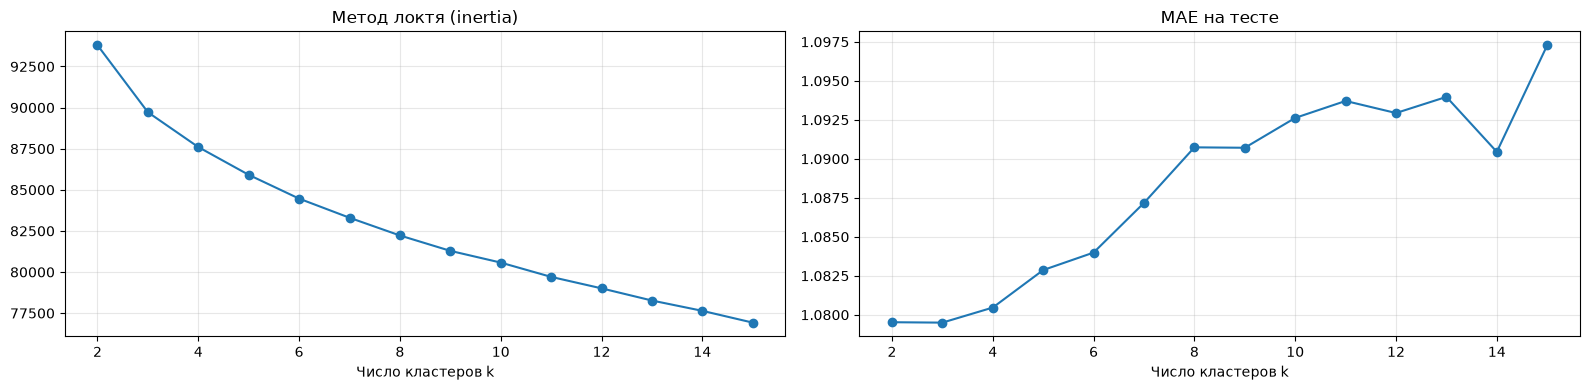

In [30]:
ks = list(range(2, 16))
inertia, sil, mae_k = [], [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(profile.values)
    inertia.append(km.inertia_)
    model = ClusterMethod(k=k).fit(X_tr, y_tr, profile)
    mae_k.append(mean_absolute_error(y_te_s, np.clip(model.predict(X_te_s), 1, 10)))
    print(f'k={k}: inertia={inertia[-1]:.0f} | MAE={mae_k[-1]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, vals, title in zip(axes, [inertia, mae_k], ['Метод локтя (inertia)', 'MAE на тесте']):
    ax.plot(ks, vals, marker='o')
    ax.set_title(title)
    ax.set_xlabel('Число кластеров k')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Кривая метода локтя убывает плавно, ярко выраженного излома нет. Практический критерий — MAE на тесте — минимален при k = 6–7 (1.0796 и 1.0798), а при k > 8 растёт: кластеры становятся мелкими, и средние оценки внутри них шумные. Поэтому выбираем **k = 6** как компромисс между детализацией групп и устойчивостью оценок.

In [49]:
best_k = 10

cluster_model = ClusterMethod(k=best_k).fit(X_tr, y_tr, profile)
pred_cluster = cluster_model.predict(X_te_s)
evaluate(f'Кластеризация (k={best_k})', y_te_s, pred_cluster)

prof_c = profile.groupby(cluster_model.user_cluster).mean()
for c in prof_c.index:
    top = prof_c.loc[c].sort_values(ascending=False).head(3).index.tolist()
    print(f'Кластер {c+1}: {(cluster_model.user_cluster == c).sum()} польз., любимые жанры: {top}')

Кластеризация (k=10): MAE = 1.0926, RMSE = 1.4135
Кластер 1: 342 польз., любимые жанры: ['Thriller', 'Police', 'Military']
Кластер 2: 188 польз., любимые жанры: ['Thriller', 'Military', 'Historical']
Кластер 3: 535 польз., любимые жанры: ['Thriller', 'Dementia', 'Police']
Кластер 4: 99 польз., любимые жанры: ['Military', 'Mecha', 'Historical']
Кластер 5: 298 польз., любимые жанры: ['Thriller', 'Military', 'Historical']
Кластер 6: 782 польз., любимые жанры: ['Historical', 'Thriller', 'Samurai']
Кластер 7: 1151 польз., любимые жанры: ['Thriller', 'Psychological', 'Game']
Кластер 8: 612 польз., любимые жанры: ['Military', 'Historical', 'Adventure']
Кластер 9: 683 польз., любимые жанры: ['Police', 'Thriller', 'Military']
Кластер 10: 310 польз., любимые жанры: ['Police', 'Thriller', 'Military']


## 3.3. Матричная факторизация (SVD и NMF)

Матрица рейтингов разреженная: пользователь оценил лишь малую часть аниме. Факторизация представляет её как произведение матриц малой размерности.

Пропуски в матрице заполняем средней оценкой пользователя, поэтому для SVD (центрированная матрица) они превращаются в нули, то есть «нет отклонения от вкуса пользователя».

Число факторов k подбираем перебором.

In [32]:
users_idx = pd.Index(sorted(X_tr['user_id'].unique()))
items_idx = pd.Index(sorted(X_tr['anime_id'].unique()))

R = np.full((len(users_idx), len(items_idx)), np.nan)
R[users_idx.get_indexer(X_tr['user_id']), items_idx.get_indexer(X_tr['anime_id'])] = y_tr

user_mean_arr = np.nanmean(R, axis=1)
R_filled = np.where(np.isnan(R), user_mean_arr[:, None], R) 
R_centered = R_filled - user_mean_arr[:, None]

def predict_from_matrix(P, X):
    u = users_idx.get_indexer(X['user_id'])
    i = items_idx.get_indexer(X['anime_id'])
    pred = np.zeros(len(X)) 
    ok = (u >= 0) & (i >= 0)
    pred[ok] = P[u[ok], i[ok]]
    return pred

print(R.shape)

(5000, 1500)


In [39]:
svd_preds = {}
for k in list(range(1, 20)):
    U, s, Vt = svds(R_centered, k=k)
    P_svd = user_mean_arr[:, None] + (U * s) @ Vt
    svd_preds[k] = P_svd
    pred = np.clip(predict_from_matrix(P_svd, X_te_s), 1, 10)
    print(f'SVD k={k}: MAE = {mean_absolute_error(y_te_s, pred):.4f}')

SVD k=1: MAE = 0.9809
SVD k=2: MAE = 0.9716
SVD k=3: MAE = 0.9663
SVD k=4: MAE = 0.9614
SVD k=5: MAE = 0.9605
SVD k=6: MAE = 0.9588
SVD k=7: MAE = 0.9577
SVD k=8: MAE = 0.9556
SVD k=9: MAE = 0.9556
SVD k=10: MAE = 0.9531
SVD k=11: MAE = 0.9526
SVD k=12: MAE = 0.9516
SVD k=13: MAE = 0.9513
SVD k=14: MAE = 0.9506
SVD k=15: MAE = 0.9500
SVD k=16: MAE = 0.9486
SVD k=17: MAE = 0.9480
SVD k=18: MAE = 0.9483
SVD k=19: MAE = 0.9484


In [40]:
best_k_svd = 10
P_svd = svd_preds[best_k_svd]
evaluate(f'SVD (k={best_k_svd})', y_te_s, predict_from_matrix(P_svd, X_te_s))

SVD (k=10): MAE = 0.9531, RMSE = 1.2635


In [43]:
nmf_preds = {}
for k in list(range(1, 21)):
    nmf = NMF(n_components=k, init='nndsvda', max_iter=300, random_state=42)
    W = nmf.fit_transform(R_filled)
    P_nmf = W @ nmf.components_
    nmf_preds[k] = P_nmf
    pred = np.clip(predict_from_matrix(P_nmf, X_te_s), 1, 10)
    print(f'NMF k={k}: MAE = {mean_absolute_error(y_te_s, pred):.4f}')

C:\Users\el_jin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\decomposition\_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


NMF k=1: MAE = 0.9988
NMF k=2: MAE = 0.9912
NMF k=3: MAE = 0.9920
NMF k=4: MAE = 0.9936
NMF k=5: MAE = 0.9950
NMF k=6: MAE = 0.9967
NMF k=7: MAE = 0.9942
NMF k=8: MAE = 0.9974
NMF k=9: MAE = 0.9973
NMF k=10: MAE = 0.9959
NMF k=11: MAE = 0.9944
NMF k=12: MAE = 0.9961
NMF k=13: MAE = 0.9923
NMF k=14: MAE = 0.9838
NMF k=15: MAE = 0.9667


C:\Users\el_jin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\decomposition\_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


NMF k=16: MAE = 0.9523
NMF k=17: MAE = 0.9747
NMF k=18: MAE = 0.9668
NMF k=19: MAE = 0.9725
NMF k=20: MAE = 0.9733


In [44]:
best_k_nmf = 20
P_nmf = nmf_preds[best_k_nmf]
evaluate(f'NMF (k={best_k_nmf})', y_te_s, predict_from_matrix(P_nmf, X_te_s))

NMF (k=20): MAE = 0.9733, RMSE = 1.2896


## 4. Сравнение результатов

Сравниваем все методы на одной и той же тестовой выборке

In [46]:
res_df = pd.DataFrame(results).T.sort_values('MAE')
display(res_df.round(4))

,MAE,RMSE
SVD (k=20),0.9477,1.2565
SVD (k=10),0.9531,1.2635
NMF (k=20),0.9733,1.2896
User-based,0.9857,1.3161
Item-based,1.0503,1.3640
Кластеризация (k=6),1.0840,1.4014
Среднее по аниме,1.1082,1.4360
Глобальное среднее,1.1772,1.5385


### Пример рекомендаций

Для наглядности покажем топ-10 аниме, которые лучший из методов матричной факторизации рекомендует случайному пользователю (среди тех, что он ещё не оценивал).

In [50]:
def recommend(user_id, P, n=10):
    u = users_idx.get_loc(user_id)
    seen = set(sub.loc[sub['user_id'] == user_id, 'anime_id'])
    scores = pd.Series(P[u], index=items_idx)
    scores = scores[~scores.index.isin(seen)]
    scores = scores[~scores.index.isin(anime.loc[anime['genre'].str.contains('Comedy'), 'anime_id'])]
    scores = scores.sort_values(ascending=False).head(n)
    out = anime.set_index('anime_id').loc[scores.index, ['name', 'genre']].copy()
    out['predicted_rate'] = scores.values.round(2)
    return out

test_user = users_idx[3]
print('Любимые аниме пользователя', test_user)
display(sub[sub['user_id'] == test_user].sort_values('rate', ascending=False).head(5)
        .merge(anime[['anime_id', 'name', 'genre']], on='anime_id')[['name', 'genre', 'rate']])

print('Рекомендации:')
display(recommend(test_user, P_svd))

Любимые аниме пользователя 71


,name,genre,rate
0,Samurai Champloo,"Action, Adventure, Comedy, Historical, Samurai...",10
1,Eureka Seven,"Adventure, Drama, Mecha, Romance, Sci-Fi",10
2,Ouran Koukou Host Club,"Comedy, Harem, Romance, School, Shoujo",10
3,Toki wo Kakeru Shoujo,"Adventure, Drama, Romance, Sci-Fi",10
4,Soul Eater,"Action, Adventure, Comedy, Fantasy, Shounen, S...",10


Рекомендации:


,name,genre,predicted_rate
1535,Death Note,"Mystery, Police, Psychological, Supernatural, ...",9.29
4181,Clannad: After Story,"Drama, Fantasy, Romance, Slice of Life, Supern...",9.15
5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",9.13
226,Elfen Lied,"Action, Drama, Horror, Psychological, Romance,...",9.06
2904,Code Geass: Hangyaku no Lelouch R2,"Action, Drama, Mecha, Military, Sci-Fi, Super ...",9.02
199,Sen to Chihiro no Kamikakushi,"Adventure, Drama, Supernatural",8.99
431,Howl no Ugoku Shiro,"Adventure, Drama, Fantasy, Romance",8.99
9253,Steins;Gate,"Sci-Fi, Thriller",8.96
22535,Kiseijuu: Sei no Kakuritsu,"Action, Drama, Horror, Psychological, Sci-Fi, ...",8.95
1889,Higurashi no Naku Koro ni Kai,"Mystery, Psychological, Supernatural, Thriller",8.95


## Выводы по работе
1. Лучший результат показал метод SVD (k=20): MAE 0.9542, что на 0.15 балла (≈14%) лучше baseline «среднее по аниме». Худшим оказался baseline «глобальное среднее».
2. Матричная факторизация показала лучшее качество, так как выделяет скрытые факторы и лучше справляется с разреженностью матрицы (заполнено лишь 8.3%). Качество SVD растёт до k≈20–50 и затем перестаёт улучшаться (при k=100 MAE снова растёт), то есть начинается переобучение. Для NMF оптимум также при k=20. SVD оказался точнее NMF, вероятно, потому что работает с центрированными данными и допускает отрицательные факторы.
3. User-based (MAE 0.9922) оказался точнее item-based (1.0485). Оба метода используют всех соседей, а не top-K наиболее похожих, что «размывает» прогноз. Ограничение числа соседей, вероятно, улучшило бы результат.
4. Модель на основе кластеризации проста, быстра и интерпретируема, но даёт наименьшую точность среди персонализированных методов (MAE 1.0796): она учитывает только жанровые предпочтения и не различает пользователей внутри одного кластера. Число кластеров k=6 выбрано по MAE (минимум при k=6–7). При k>8 качество ухудшается из-за нехватки оценок в мелких кластерах. Профили кластеров получились похожими (везде выделяются Thriller, Military, Police), так как средние по редким жанрам шумные.
5. Ограничения: число факторов и кластеров подбиралось по тестовой выборке (в идеале нужна отдельная валидация); эксперимент проведён на подвыборке данных; метрики MAE/RMSE не оценивают качество ранжирования (Precision@K, NDCG). Пример рекомендаций показывает смещение в сторону популярных аниме.

Итог: для данной задачи предпочтительнее матричная факторизация (SVD), а простую кластерную модель разумно использовать как быстрый интерпретируемый вариант для новых пользователей.